# EDA

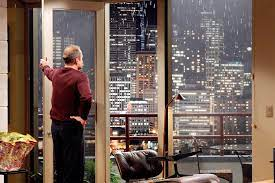

## 1. Projektstart

### Stakeholder
Zachary Brooks (Verkäufer): Investiert in historische Häuser in den besten Lagen von King County. Er will hohe Profite, den besten Verkaufszeitpunkt innerhalb eines Jahres und wissen, ob sich eine Renovierung lohnt.

### Geschäftsziel / Fragestellung
Wie kann Zachary Brooks mit historischen Häusern in Top-Lagen seinen Gewinn maximieren, und welche Rolle spielen dabei Renovierung und Verkaufszeitpunkt?

### Hypothesen

| | Hypothese | Relevante Spalten |
|---|---|---|
| **H1** | Historische Häuser erzielen in Top-Lagen einen höheren Preis pro sqft als neuere Häuser in denselben Zipcodes. | `yr_built`, `price`, `sqft_living`, `zipcode` |
| **H2** | Renovierte Häuser erzielen höhere Verkaufspreise als vergleichbare nicht renovierte Häuser. Der Effekt ist bei historischen Häusern besonders stark. | `yr_renovated`, `condition`, `grade`, `price` |
| **H3** | Verkäufe zwischen März und August erzielen höhere Preise (Median-Preis bzw. Preis pro sqft) als Verkäufe zwischen September und Februar. | `date`, `price` |

### Annahmen
- **Historisch:** Baujahr vor 1950 (Vorkriegs- und frühe Nachkriegszeit). Die Grenze wird auf Robustheit mit 1930, 1940 und 1960 verglichen.
- **Top-Lage:** Zipcodes, deren Median-Verkaufspreis im obersten Dezil (obere 10 %) aller Zipcodes liegt.
- **Renovierung:** `yr_renovated > 0` gilt als renoviert, `0` als nicht renoviert. Fehlende Werte (`NaN`) gelten als unbekannt und werden bei H2 nicht berücksichtigt.
- **Profit:** Der Datensatz enthält nur Verkaufspreise, keine Einkaufs- oder Renovierungskosten. Als Näherung dienen Preis und Preis pro sqft.
- **Mehrfachverkäufe:** 177 Häuser wurden im Zeitraum zweimal verkauft. Jeder Verkauf zählt als eigener Datenpunkt.
- **Hochsaison:** März bis August, alle anderen Monate gelten als Nebensaison.

### Limitationen
- Der Datensatz deckt nur ca. ein Jahr ab (02.05.2014 bis 27.05.2015). Saisonalität lässt sich daher nicht von einem allgemeinen Preistrend trennen.
- Die Hochsaison-Gruppe stammt aus zwei verschiedenen Jahren (Mai bis August 2014 und März bis Mai 2015).
- Bei `yr_renovated` fehlen rund 18 % der Werte, und die Zahl renovierter Häuser ist vergleichsweise klein.

In [217]:
# Haus-DataFrame der Top-Zipcodes neu aufbauen (die Heatmap hatte "top" mit Kartenflächen überschrieben)
top = df[df["top_zip"]].copy()
top["ppsf_rel"] = top["price_per_sqft"] / top.groupby("zipcode")["price_per_sqft"].transform("median")

In [122]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

## 2. Daten laden und erster Überblick 

In [123]:
df = pd.read_csv("data/king_county_joined.csv")
print(df.shape)
df.head()

(21597, 22)


,sale_id,house_id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,1,7129300520,2014-10-13,221900.000,3.000,1.000,1180.000,5650.000,1.000,NaN,...,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,2,6414100192,2014-12-09,538000.000,3.000,2.250,2570.000,7242.000,2.000,0.000,...,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,3,5631500400,2015-02-25,180000.000,2.000,1.000,770.000,10000.000,1.000,0.000,...,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,4,2487200875,2014-12-09,604000.000,4.000,3.000,1960.000,5000.000,1.000,0.000,...,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,5,1954400510,2015-02-18,510000.000,3.000,2.000,1680.000,8080.000,1.000,0.000,...,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


In [124]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sale_id        21597 non-null  int64  
 1   house_id       21597 non-null  int64  
 2   date           21597 non-null  str    
 3   price          21597 non-null  float64
 4   bedrooms       21597 non-null  float64
 5   bathrooms      21597 non-null  float64
 6   sqft_living    21597 non-null  float64
 7   sqft_lot       21597 non-null  float64
 8   floors         21597 non-null  float64
 9   waterfront     19206 non-null  float64
 10  view           21534 non-null  float64
 11  condition      21597 non-null  int64  
 12  grade          21597 non-null  int64  
 13  sqft_above     21597 non-null  float64
 14  sqft_basement  21145 non-null  float64
 15  yr_built       21597 non-null  int64  
 16  yr_renovated   17749 non-null  float64
 17  zipcode        21597 non-null  int64  
 18  lat            21

In [125]:
df.isna().sum()

sale_id             0
house_id            0
date                0
price               0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       2391
view               63
condition           0
grade               0
sqft_above          0
sqft_basement     452
yr_built            0
yr_renovated     3848
zipcode             0
lat                 0
long                0
sqft_living15       0
sqft_lot15          0
dtype: int64

## 3. Data Cleaning

In [126]:
# Wandelt den Text in der Spalte "date" in ein echtes Datum um
df["date"] = pd.to_datetime(df["date"])

In [127]:
# Zählt Zeilen, die komplett doppelt vorkommen
df.duplicated().sum()

np.int64(0)

In [128]:
# Zählt Häuser (house_id), die mehr als einmal verkauft wurden
df["house_id"].duplicated().sum()

np.int64(177)

In [129]:
# Zeigt, wie oft jeder Wert vorkommt (inkl. NaN), nur die häufigsten 10
df["yr_renovated"].value_counts(dropna=False).head(10)

yr_renovated
0.000        17005
NaN           3848
20140.000       73
20130.000       31
20030.000       31
20070.000       30
20050.000       29
20000.000       29
19900.000       22
20040.000       22
Name: count, dtype: int64

In [130]:
# Teilt alle Werte größer 0 durch 10, damit aus 20140.0 das Jahr 2014 wird (NaN und 0 bleiben unverändert)
df["yr_renovated"] = df["yr_renovated"].where(df["yr_renovated"].isna() | (df["yr_renovated"] == 0), df["yr_renovated"] / 10)

In [131]:
# Prüft, ob jetzt realistische Jahre (z. B. 1934 bis 2015) herauskommen
df["yr_renovated"].replace(0, pd.NA).dropna().agg(["min", "max"])

min   1934.000
max   2015.000
Name: yr_renovated, dtype: float64

In [132]:
# Erstellt eine Hilfsspalte: "ja" wenn Renovierungsjahr > 0, "nein" wenn 0, sonst unbekannt (NaN) weil zu viele Daten zum löschen.
df["renovated"] = df["yr_renovated"].apply(lambda x: pd.NA if pd.isna(x) else (x > 0))

In [133]:
# Zählt, wie viele Häuser renoviert, nicht renoviert oder unbekannt sind
df["renovated"].value_counts(dropna=False)

renovated
False    17005
<NA>      3848
True       744
Name: count, dtype: int64

In [134]:
# Frühestes und spätestes Verkaufsdatum im Datensatz
df["date"].min(), df["date"].max()

(Timestamp('2014-05-02 00:00:00'), Timestamp('2015-05-27 00:00:00'))

## 4. Feature Engineering und Annahmen

In [135]:
# Preis pro Quadratfuß Wohnfläche (für H1 und H3)
df["price_per_sqft"] = df["price"] / df["sqft_living"]

In [136]:
# Verkaufsmonat als Zahl 1 bis 12 (für H3)
df["month"] = df["date"].dt.month

In [137]:
# Markiert Verkäufe von März bis August als "Hochsaison", alle anderen als "Nebensaison" (für H3)
df["season"] = df["month"].apply(lambda m: "Hochsaison" if 3 <= m <= 8 else "Nebensaison")

In [138]:
# Markiert historische Häuser (Baujahr vor 1940) für H1
df["historic"] = df["yr_built"] < 1940

In [139]:
# Zählt renovierte und nicht renovierte Häuser getrennt für historische (True) und neuere (False) Häuser (vorher die Spalte "historic" aus dem letzten Schritt anlegen)
df["historic"] = df["yr_built"] < 1940
df.groupby("historic")["renovated"].value_counts()

historic  renovated
False     False        14757
          True           398
True      False         2248
          True           346
Name: count, dtype: int64

In [140]:
# Zählt Häuser pro Altersgrenze (vor 1930, 1940, 1950, 1960), um die Stichprobengröße zu vergleichen
for grenze in [1930, 1940, 1950, 1960]:
    print(grenze, (df["yr_built"] < grenze).sum())

1930 2642
1940 3172
1950 4935
1960 7385


In [141]:
# Zählt renovierte Häuser pro Altersgrenze (nur True), um die Stichprobe für H2 zu sehen
for grenze in [1930, 1940, 1950, 1960]:
    print(grenze, ((df["yr_built"] < grenze) & (df["renovated"] == True)).sum())

1930 274
1940 346
1950 470
1960 600


### 4.1 Top-Zipcodes
**Annahme:** Top-Lage = Zipcodes, deren Median-Verkaufspreis im obersten Dezil aller Zipcodes liegt.

In [142]:
# Median-Verkaufspreis pro Zipcode berechnen
zip_median = df.groupby("zipcode")["price"].median()

In [143]:
# Schwellenwert: das 90%-Quantil der Zipcode-Mediane (alles darüber = Top 10 %)
threshold = zip_median.quantile(0.9)

In [144]:
# Liste der Top-Zipcodes (Median-Preis liegt auf oder über dem Schwellenwert)
top_zips = zip_median[zip_median >= threshold].index
print(len(top_zips), sorted(top_zips))

7 [98004, 98005, 98006, 98039, 98040, 98112, 98119]


In [145]:
# Neue Spalte: True, wenn das Haus in einem Top-Zipcode liegt
df["top_zip"] = df["zipcode"].isin(top_zips)

In [146]:
# Zählt, wie viele Verkäufe in Top-Zipcodes liegen
df["top_zip"].value_counts()

top_zip
False    19829
True      1768
Name: count, dtype: int64

**Ergebnis:** 7 von rund 70 Zipcodes zählen als Top-Lage (98004, 98005, 98006, 98039, 98040, 98112, 98119). 
Sie enthalten 1.768 Verkäufe (ca. 8 % aller Verkäufe).

### 4.2 Historische Häuser und Stichprobengröße
**Annahme:** Historisch = Baujahr vor 1950 (Vorkriegs- und frühe Nachkriegszeit).

In [147]:
# Zählt Häuser nach Kombination: Top-Zipcode, historisch (<1950) und renoviert-Status
df["historic"] = df["yr_built"] < 1950
df[df["top_zip"]].groupby("historic")["renovated"].value_counts(dropna=False)

historic  renovated
False     False        1112
          NaN           245
          True           62
True      False         232
          True           62
          NaN            55
Name: count, dtype: int64

**Ergebnis:** In Top-Zipcodes gibt es 349 historische Häuser (davon 62 renoviert, 232 nicht renoviert, 55 unbekannt). Für H1 ist die Stichprobe ausreichend. 
Für H2 ist sie bei historischen Häusern klein, daher wird H2 zusätzlich über alle Top-Zipcode-Häuser geprüft.

## 5. Hypothese 1: Historische Häuser erzielen in Top-Lagen einen höheren Preis pro sqft

**Vorgehen:** Wir vergleichen den Preis pro sqft Wohnfläche von historischen (Baujahr vor 1950) und neueren Häusern, jeweils nur innerhalb der Top-Zipcodes. So wird der Lageeffekt herausgerechnet.

In [148]:
# Filtert den Datensatz auf Verkäufe in Top-Zipcodes und legt sie in einem eigenen DataFrame ab
top = df[df["top_zip"]].copy()

In [149]:
# Gruppiert nach historisch (True) und neuer (False) und berechnet Anzahl, Median und Mittelwert von Preis pro sqft
top.groupby("historic")["price_per_sqft"].agg(["count", "median", "mean"])

,count,median,mean
historic,,,
False,1419,347.826,374.049
True,349,431.250,450.358


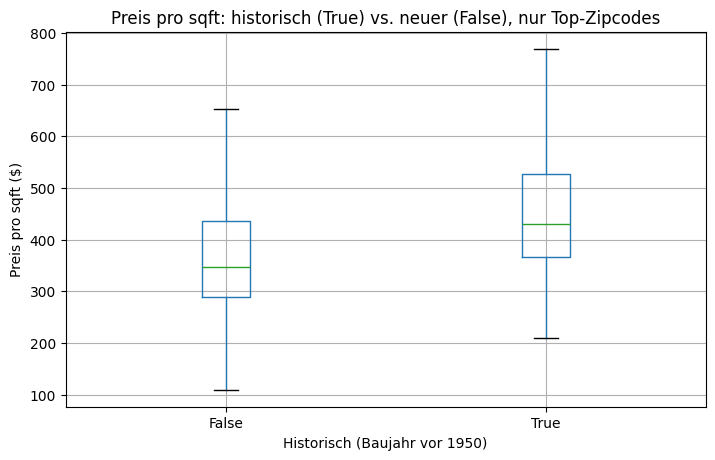

In [150]:
# Zeichnet einen Boxplot des Preises pro sqft für historische und neuere Häuser in Top-Zipcodes
top.boxplot(column="price_per_sqft", by="historic", showfliers=False)
plt.title("Preis pro sqft: historisch (True) vs. neuer (False), nur Top-Zipcodes")
plt.suptitle("")
plt.xlabel("Historisch (Baujahr vor 1950)")
plt.ylabel("Preis pro sqft ($)")
plt.show()

In [151]:
# Median Preis pro sqft je Top-Zipcode, getrennt nach historisch und neuer
top.groupby(["zipcode", "historic"])["price_per_sqft"].median().unstack()

historic,False,True
zipcode,,
98004,450.868,528.620
98005,316.340,379.293
98006,288.233,293.338
98039,565.359,530.303
98040,374.408,403.509
98112,427.488,422.222
98119,400.000,430.070


In [152]:
# Mann-Whitney-U-Test: Unterscheiden sich die Preise pro sqft von historischen und neueren Häusern signifikant?
from scipy.stats import mannwhitneyu

hist = top[top["historic"]]["price_per_sqft"]
neu = top[~top["historic"]]["price_per_sqft"]
mannwhitneyu(hist, neu, alternative="greater")

MannwhitneyuResult(statistic=np.float64(340806.5), pvalue=np.float64(5.351985656374562e-28))

In [153]:
# Wiederholt den Vergleich mit anderen Altersgrenzen, um die Robustheit des Ergebnisses zu prüfen
for grenze in [1930, 1940, 1950, 1960]:
    alt = top[top["yr_built"] < grenze]["price_per_sqft"].median()
    jung = top[top["yr_built"] >= grenze]["price_per_sqft"].median()
    print(grenze, round(alt, 1), round(jung, 1))

1930 432.0 353.2
1940 433.6 351.2
1950 431.2 347.8
1960 413.7 341.0


## Lageeffekt herausrechnen: 


In [154]:
# Anteil historischer Häuser pro Top-Zipcode (sum = Anzahl historisch, count = alle, mean = Anteil)
top.groupby("zipcode")["historic"].agg(["sum", "count", "mean"])

,sum,count,mean
zipcode,,,
98004,25,317,0.079
98005,2,168,0.012
98006,6,498,0.012
98039,7,50,0.140
98040,19,282,0.067
98112,173,269,0.643
98119,117,184,0.636


In [155]:
# Median Wohnfläche: Sind historische Häuser kleiner (das würde den Preis pro sqft erhöhen)?
top.groupby("historic")["sqft_living"].median()

historic
False   2680.000
True    2160.000
Name: sqft_living, dtype: float64

In [156]:
# Preis pro sqft relativ zum Median der eigenen Zipcode (1.0 = typisch für die Zipcode)
top["ppsf_rel"] = top["price_per_sqft"] / top.groupby("zipcode")["price_per_sqft"].transform("median")
top.groupby("historic")["ppsf_rel"].agg(["count", "median", "mean"])

,count,median,mean
historic,,,
False,1419,0.995,1.022
True,349,1.022,1.071


In [157]:
# Mann-Whitney-Test auf den lagebereinigten Werten
hist_rel = top[top["historic"]]["ppsf_rel"]
neu_rel = top[~top["historic"]]["ppsf_rel"]
mannwhitneyu(hist_rel, neu_rel, alternative="greater")

MannwhitneyuResult(statistic=np.float64(269749.5), pvalue=np.float64(0.004792719284178445))

**Ergebnis:** Über alle Top-Zipcodes liegt der Median-Preis pro sqft historischer Häuser (Baujahr vor 1950) bei ca. 431 \$, bei neueren Häusern bei ca. 348 \$ (Mann-Whitney-Test, p < 0.001). Das Ergebnis ist robust gegenüber der Altersgrenze (1930 bis 1960). Der Gesamtunterschied ist jedoch größtenteils ein Lageeffekt: 290 der 349 historischen Häuser (83 %) liegen in nur zwei Zipcodes (98112 und 98119) mit hohem Preisniveau. Innerhalb der einzelnen Zipcodes sind historische Häuser nur in 5 von 7 Zipcodes teurer, und der Aufschlag liegt zwischen -6 % und +20 %.

Nach Lagebereinigung (Preis pro sqft relativ zum Median der eigenen Zipcode) bleibt ein kleiner Aufschlag von ca. 2,7 Prozentpunkten (Median 1,022 gegen 0,995, Mann-Whitney-Test p = 0,005). Historische Häuser sind zudem rund 20 % kleiner (Median 2.160 gegen 2.680 sqft), was den Preis pro sqft zusätzlich erhöhen kann.

**Fazit für Zachary:** H1 ist nur eingeschränkt bestätigt. Das Alter allein bringt in Top-Lagen nur einen geringen Aufschlag von etwa 2 bis 3 %. Entscheidend ist die Lage: Historische Häuser in den Seattle-Zipcodes 98112 und 98119 erzielen hohe Preise, weil dort das Preisniveau insgesamt hoch ist. Ein hoher Preis pro sqft allein ist daher kein Argument, ein Haus nur wegen seines Alters zu kaufen.

## 6. Hypothese 2: Renovierte Häuser erzielen höhere Preise

**Vorgehen:** Wir vergleichen renovierte (`yr_renovated > 0`) mit nicht renovierten Häusern. Häuser mit unbekanntem Renovierungsstatus (`NaN`) werden ausgeschlossen. Um Lage- und Größeneffekte herauszurechnen, nutzen wir neben dem Preis auch den lagebereinigten Preis pro sqft (`ppsf_rel`). Zuerst für alle Top-Zipcode-Häuser, danach getrennt nach historisch und neuer.

In [158]:
# Top-Zipcode-Häuser mit bekanntem Renovierungsstatus (NaN ausgeschlossen); renovated als bool umwandeln
h2 = top[top["renovated"].notna()].copy()
h2["renovated"] = h2["renovated"].astype(bool)

In [159]:
# Anzahl, Median-Preis, Median-Wohnfläche und lagebereinigter Preis pro sqft für renoviert (True) vs. nicht renoviert (False)
h2.groupby("renovated").agg(
    anzahl=("price", "count"),
    median_preis=("price", "median"),
    median_sqft=("sqft_living", "median"),
    median_ppsf_rel=("ppsf_rel", "median"),
)

,anzahl,median_preis,median_sqft,median_ppsf_rel
renovated,,,,
False,1344,865000.000,2560.000,0.991
True,124,1095000.000,2745.000,1.042


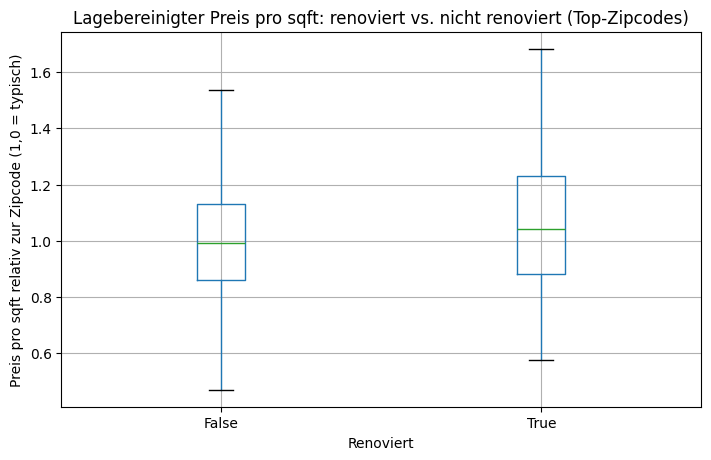

In [160]:
# Boxplot von ppsf_rel (1,0 = typisch für die eigene Zipcode) für renoviert vs. nicht renoviert
h2.boxplot(column="ppsf_rel", by="renovated", showfliers=False)
plt.title("Lagebereinigter Preis pro sqft: renoviert vs. nicht renoviert (Top-Zipcodes)")
plt.suptitle("")
plt.xlabel("Renoviert")
plt.ylabel("Preis pro sqft relativ zur Zipcode (1,0 = typisch)")
plt.show()

In [161]:
# Mann-Whitney-U-Test: Haben renovierte Häuser einen höheren lagebereinigten Preis pro sqft?
ren = h2[h2["renovated"]]["ppsf_rel"]
nicht_ren = h2[~h2["renovated"]]["ppsf_rel"]
mannwhitneyu(ren, nicht_ren, alternative="greater")

MannwhitneyuResult(statistic=np.float64(92717.0), pvalue=np.float64(0.018828265395736732))

In [162]:
# Sind renovierte Häuser auch in Zustand (condition) und Bauqualität (grade) anders? Mittelwerte je Gruppe
h2.groupby("renovated")[["condition", "grade", "yr_built"]].mean()

,condition,grade,yr_built
renovated,,,
False,3.632,8.656,1968.415
True,3.282,8.556,1943.540


In [163]:
# Lagebereinigter Preis pro sqft, getrennt nach historisch und renoviert (Anzahl, Median)
h2.groupby(["historic", "renovated"])["ppsf_rel"].agg(["count", "median"]).unstack()

count       median      
renovated False True   False True 
historic                          
False      1112    62  0.984 1.045
True        232    62  1.019 1.003

In [164]:
# Mann-Whitney-Test nur für historische Häuser (renoviert vs. nicht renoviert)
hist_h2 = h2[h2["historic"]]
mannwhitneyu(
    hist_h2[hist_h2["renovated"]]["ppsf_rel"],
    hist_h2[~hist_h2["renovated"]]["ppsf_rel"],
    alternative="greater",
)

MannwhitneyuResult(statistic=np.float64(7112.5), pvalue=np.float64(0.5535095684171061))

In [165]:
# Gleicher Vergleich über alle Zipcodes (nicht nur Top), um zu prüfen, ob das Ergebnis mit mehr Daten stabil ist
alle = df[df["renovated"].notna()].copy()
alle["renovated"] = alle["renovated"].astype(bool)
alle["ppsf_rel_all"] = alle["price_per_sqft"] / alle.groupby("zipcode")["price_per_sqft"].transform("median")
alle.groupby("renovated")["ppsf_rel_all"].agg(["count", "median"])

,count,median
renovated,,
False,17005,0.999
True,744,1.041


**Ergebnis:** Lagebereinigt erzielen renovierte Häuser in den Top-Zipcodes einen Preis pro sqft von 1,042 relativ zur eigenen Zipcode, nicht renovierte von 0,991 (Mann-Whitney-Test, p = 0,019). Über alle Zipcodes (744 renovierte Häuser) zeigt sich dasselbe Bild (1,041 gegen 0,999). Der Aufschlag beträgt also rund 4 bis 5 Prozentpunkte.

Der zweite Teil der Hypothese wird nicht bestätigt: Bei historischen Häusern in Top-Lagen gibt es keinen nachweisbaren Renovierungsaufschlag (1,003 gegen 1,019, p = 0,55; nur 62 renovierte Fälle). Der Effekt stammt aus den nicht historischen Häusern (1,045 gegen 0,984).

**Limitationen:** Renovierungskosten, Umfang und Zeitpunkt der Renovierung sind nicht bekannt. Renovierte Häuser haben im Schnitt einen niedrigeren `condition`-Wert (3,28 gegen 3,63). Die Stichprobe renovierter historischer Häuser ist klein.

**Fazit für Zachary:** Eine Renovierung bringt im Schnitt einen moderaten Preisaufschlag von etwa 4 bis 5 %. Bei historischen Häusern ist dieser Aufschlag in den Daten nicht nachweisbar. Eine Renovierung sollte daher nur eingeplant werden, wenn die Kosten deutlich unter dem erwartbaren Aufschlag liegen.

## 7. Hypothese 3: Verkäufe in der Hochsaison (März bis August) erzielen höhere Preise

**Vorgehen:** Wir vergleichen Hochsaison (März bis August) mit Nebensaison (September bis Februar), zuerst über den gesamten Datensatz, danach nur für Top-Zipcodes und historische Häuser. Zusätzlich betrachten wir die Monatsmediane, um einen allgemeinen Preistrend von einem Saisoneffekt zu unterscheiden. Preise werden nominal verwendet, der Zeitraum umfasst nur ca. 13 Monate.

In [166]:
# Preis pro sqft relativ zum Median der eigenen Zipcode (1,0 = typisch), für alle Verkäufe
df["ppsf_rel_all"] = df["price_per_sqft"] / df.groupby("zipcode")["price_per_sqft"].transform("median")

In [167]:
# Anzahl, Median-Preis und Median lagebereinigter Preis pro sqft je Saison
df.groupby("season").agg(
    anzahl=("price", "count"),
    median_preis=("price", "median"),
    median_ppsf=("price_per_sqft", "median"),
    median_ppsf_rel=("ppsf_rel_all", "median"),
)

,anzahl,median_preis,median_ppsf,median_ppsf_rel
season,,,,
Hochsaison,12846,460000.000,248.597,1.008
Nebensaison,8751,439000.000,238.756,0.988


In [168]:
# Median-Preis und lagebereinigter Preis pro sqft je Verkaufsmonat, chronologisch (Jahr-Monat)
monat = df.groupby(df["date"].dt.to_period("M")).agg(
    anzahl=("price", "count"),
    median_preis=("price", "median"),
    median_ppsf_rel=("ppsf_rel_all", "median"),
)
monat

,anzahl,median_preis,median_ppsf_rel
date,,,
2014-05,1768,465000.000,0.977
2014-06,2178,465000.000,0.993
2014-07,2211,465000.000,0.989
2014-08,1939,442200.000,0.982
2014-09,1771,450000.000,0.980
2014-10,1876,447000.000,0.973
2014-11,1409,435000.000,0.989
2014-12,1470,432500.000,0.983
2015-01,978,438500.000,1.000


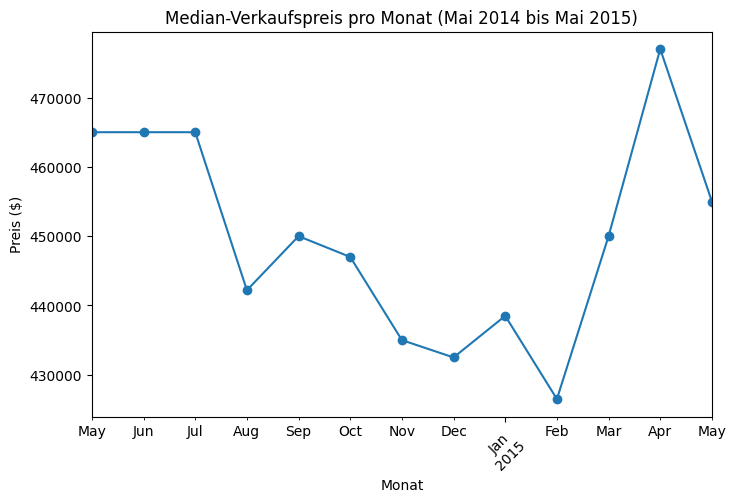

In [169]:
# Liniendiagramm der Monatsmediane: Peak im Frühjahr/Sommer = Saisonalität, durchgehender Anstieg = Markttrend
monat["median_preis"].plot(marker="o")
plt.title("Median-Verkaufspreis pro Monat (Mai 2014 bis Mai 2015)")
plt.xlabel("Monat")
plt.ylabel("Preis (\$)")
plt.xticks(rotation=45)
plt.show()

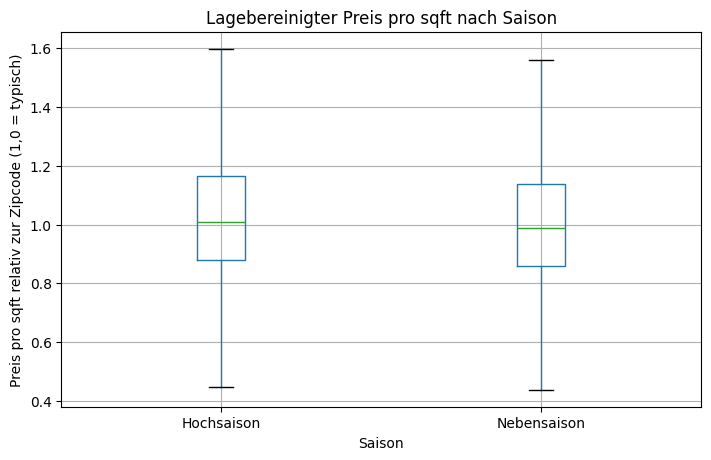

In [170]:
# Boxplot des lagebereinigten Preises pro sqft für Hochsaison vs. Nebensaison
df.boxplot(column="ppsf_rel_all", by="season", showfliers=False)
plt.title("Lagebereinigter Preis pro sqft nach Saison")
plt.suptitle("")
plt.xlabel("Saison")
plt.ylabel("Preis pro sqft relativ zur Zipcode (1,0 = typisch)")
plt.show()

In [171]:
# Mann-Whitney-U-Test: Ist der Preis in der Hochsaison höher? (einmal absoluter Preis, einmal lagebereinigt)
hoch = df[df["season"] == "Hochsaison"]
neben = df[df["season"] == "Nebensaison"]
print(mannwhitneyu(hoch["price"], neben["price"], alternative="greater"))
print(mannwhitneyu(hoch["ppsf_rel_all"], neben["ppsf_rel_all"], alternative="greater"))

MannwhitneyuResult(statistic=np.float64(59257621.5), pvalue=np.float64(5.985589163258592e-12))
MannwhitneyuResult(statistic=np.float64(59413927.5), pvalue=np.float64(5.091106758942001e-13))


In [172]:
# Gleicher Saisonvergleich für Top-Zipcodes und für historische Häuser in Top-Zipcodes (Anzahl, Median Preis, Median ppsf_rel)
for name, daten in [("Top-Zipcodes", df[df["top_zip"]]), ("Top + historisch", df[df["top_zip"] & df["historic"]])]:
    print(name)
    print(daten.groupby("season").agg(
        anzahl=("price", "count"),
        median_preis=("price", "median"),
        median_ppsf_rel=("ppsf_rel_all", "median"),
    ), "\n")

Top-Zipcodes
             anzahl  median_preis  median_ppsf_rel
season                                            
Hochsaison     1081    900000.000            1.006
Nebensaison     687    850000.000            0.984 

Top + historisch
             anzahl  median_preis  median_ppsf_rel
season                                            
Hochsaison      215    915000.000            1.040
Nebensaison     134    804000.000            0.988 



In [173]:
# Mai 2014 und Mai 2015 sind der einzige Monat mit Daten aus beiden Jahren: Hinweis auf den Jahrestrend
df[df["month"] == 5].groupby(df["date"].dt.year)["price"].agg(["count", "median"])

,count,median
date,,
2014,1768,465000.000
2015,646,455000.000


**Ergebnis:** Verkäufe in der Hochsaison (März bis August) erzielen einen um ca. 5 % höheren Median-Preis (460.000 \$ gegen 439.000 \$) und einen um ca. 2 Prozentpunkte höheren lagebereinigten Preis pro sqft (1,008 gegen 0,988). Beide Unterschiede sind statistisch signifikant (Mann-Whitney-Test, p < 0.001). In den Top-Zipcodes liegt der Aufschlag bei ca. 6 % (900.000 \$ gegen 850.000 \$).

Die Monatsmediane zeigen einen Tiefpunkt im Februar 2015 (426.500 \$) und einen Peak im April 2015 (477.000 \$). Der lagebereinigte Preis pro sqft steigt jedoch von Mai 2014 (0,977) bis Mai 2015 (1,088) fast durchgehend. Ein Teil des Saisonunterschieds ist daher vermutlich ein allgemeiner Preistrend, weil die Hochsaison-Gruppe die späten Monate (März bis Mai 2015) enthält.

**Limitationen:** Der Datensatz umfasst nur ca. 13 Monate. Saisonalität und Markttrend lassen sich nicht sicher trennen. Mai 2015 hat nur 646 Verkäufe (Datensatz endet am 27.05.). Preise sind nominal.

**Fazit für Zachary:** H3 ist tendenziell bestätigt. Ein Verkauf im Frühjahr/Sommer erzielt in den Daten rund 5 % höhere Preise als im Herbst/Winter, besonders der Zeitraum April war stark, der Februar am schwächsten. Wegen des kurzen Zeitraums ist der Effekt aber nicht sicher von einem allgemeinen Preisanstieg zu trennen. Als Empfehlung: Verkauf möglichst im Frühjahr (März bis Juni) planen und Winter meiden.

## 8. Geografischer Insight

**Vorgehen:** Wir visualisieren die Verkäufe nach Koordinaten (`lat`/`long`) und vergleichen die Median-Preise der Zipcodes. So wird sichtbar, wo die Top-Lagen liegen und wo sich historische Häuser konzentrieren.

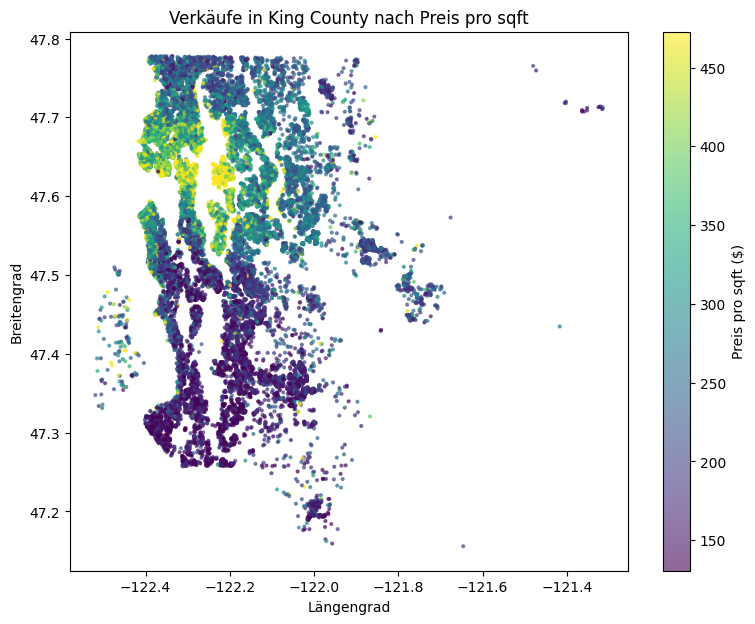

In [179]:
# Streudiagramm aller Verkäufe nach Längen- und Breitengrad, Farbe = Preis pro sqft (auf 5. bis 95. Perzentil begrenzt, damit Ausreißer die Skala nicht dominieren)
plt.figure(figsize=(9, 7))
sc = plt.scatter(
    df["long"], df["lat"],
    c=df["price_per_sqft"], cmap="viridis", s=4, alpha=0.6,
    vmin=df["price_per_sqft"].quantile(0.05), vmax=df["price_per_sqft"].quantile(0.95),
)
plt.colorbar(sc, label="Preis pro sqft (\$)")
plt.title("Verkäufe in King County nach Preis pro sqft")
plt.xlabel("Längengrad")
plt.ylabel("Breitengrad")
plt.show()

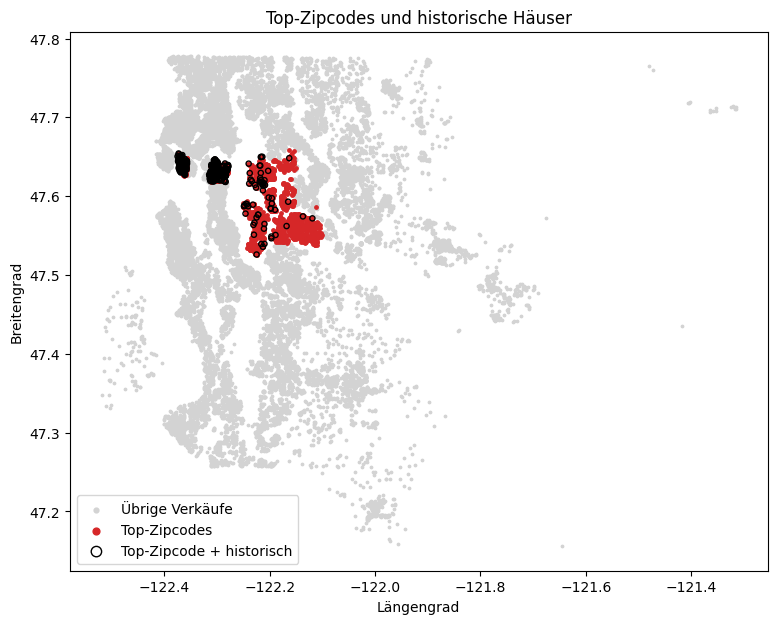

In [180]:
# Alle Verkäufe grau, Top-Zipcodes rot, historische Häuser in Top-Zipcodes schwarz umrandet
plt.figure(figsize=(9, 7))
plt.scatter(df["long"], df["lat"], s=3, color="lightgrey", label="Übrige Verkäufe")
plt.scatter(df[df["top_zip"]]["long"], df[df["top_zip"]]["lat"], s=6, color="tab:red", label="Top-Zipcodes")
h = df[df["top_zip"] & df["historic"]]
plt.scatter(h["long"], h["lat"], s=14, facecolors="none", edgecolors="black", label="Top-Zipcode + historisch")
plt.legend(markerscale=2)
plt.title("Top-Zipcodes und historische Häuser")
plt.xlabel("Längengrad")
plt.ylabel("Breitengrad")
plt.show()

In [181]:
# Die 10 Zipcodes mit dem höchsten Median-Preis, inkl. Anzahl Verkäufe und Anteil historischer Häuser
zip_tab = df.groupby("zipcode").agg(
    anzahl=("price", "count"),
    median_preis=("price", "median"),
    median_ppsf=("price_per_sqft", "median"),
    anteil_historisch=("historic", "mean"),
).sort_values("median_preis", ascending=False)
zip_tab.head(10)

,anzahl,median_preis,median_ppsf,anteil_historisch
zipcode,,,,
98039,50,1895000.000,565.166,0.140
98004,317,1150000.000,456.944,0.079
98040,282,993750.000,376.371,0.067
98112,269,915000.000,424.242,0.643
98005,168,765475.000,316.340,0.012
98006,498,760184.500,288.233,0.012
98119,184,744975.000,416.653,0.636
98075,359,739999.000,250.830,0.006
98109,109,736000.000,427.696,0.679


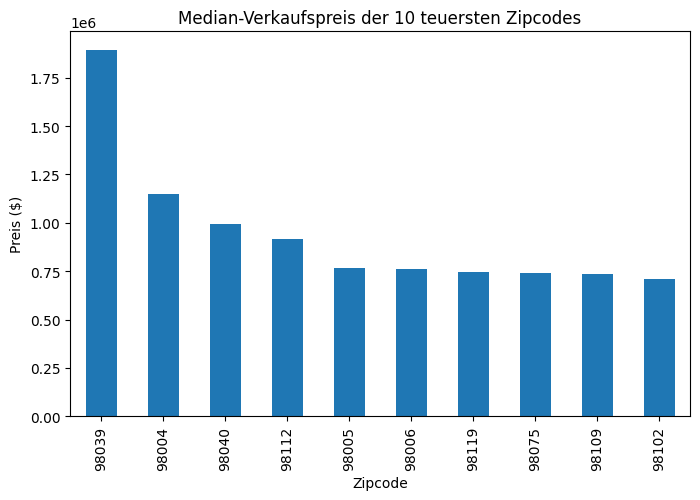

In [182]:
# Median-Preis der Top-10-Zipcodes als Balkendiagramm
zip_tab.head(10)["median_preis"].plot(kind="bar")
plt.title("Median-Verkaufspreis der 10 teuersten Zipcodes")
plt.xlabel("Zipcode")
plt.ylabel("Preis (\$)")
plt.show()

In [183]:
# Zipcodes mit den meisten historischen Häusern (mind. 30), mit Median-Preis und Median-Preis pro sqft
hist_zip = df[df["historic"]].groupby("zipcode").agg(
    anzahl=("price", "count"),
    median_preis=("price", "median"),
    median_ppsf=("price_per_sqft", "median"),
).query("anzahl >= 30").sort_values("median_ppsf", ascending=False)
hist_zip.head(10)

,anzahl,median_preis,median_ppsf
zipcode,,,
98109,74,775000.000,452.321
98119,117,800000.000,430.070
98112,173,915000.000,422.222
98102,58,832500.000,396.222
98105,177,672324.000,392.473
98033,40,617900.000,391.692
98107,131,550000.000,390.347
98199,170,678000.000,383.920
98103,349,588000.000,383.142


**Ergebnis:** Die 7 Top-Zipcodes (98004, 98005, 98006, 98039, 98040, 98112, 98119) machen nur ca. 8 % der Verkäufe aus und bilden zwei Cluster: Seattle-Zentrum (98112, 98119) und Eastside östlich des Lake Washington (98004, 98005, 98006, 98039, 98040). Die höchsten Preise pro sqft erzielt der Westen von King County rund um Seattle, nach Süden und Osten fallen sie deutlich ab.

Der teuerste Zipcode ist 98039 (Mercer Island) mit einem Median-Preis von 1.895.000 \$ und 565 \$ pro sqft, dort gibt es aber nur 50 Verkäufe und wenige historische Häuser (14 %). Historische Häuser konzentrieren sich dagegen in den Seattle-Zipcodes: Anteil 64 % in 98112 und 98119, 68 % in 98109, 56 % in 98102. Der Median-Preis pro sqft historischer Häuser ist in 98109 (452 \$), 98119 (430 \$) und 98112 (422 \$) am höchsten. In den Eastside-Top-Zipcodes sind historische Häuser dagegen selten (1 bis 8 %).

**Hinweis zur Definition:** Die Top-Lage wurde über den absoluten Median-Preis bestimmt. Die Seattle-Zipcodes 98109 und 98102 (Median 736.000 \$ bzw. 710.000 \$) liegen knapp darunter, haben aber einen hohen Preis pro sqft und viele historische Häuser. Für Zachary sind sie relevante Kandidaten.

**Fazit für Zachary:** Historische Häuser gibt es vor allem in Seattle-Zentrum-Zipcodes, die Eastside bietet kaum historischen Bestand. Wer historische Häuser in Top-Lagen sucht, findet sie in 98112, 98119 sowie ergänzend in 98109 und 98102.

## 9. Insights und Empfehlungen für Zachary Brooks

### Insights
1. **Die Lage bestimmt den Preis, nicht das Alter.** Der Gesamtunterschied im Preis pro sqft zwischen historischen (431 \$) und neueren Häusern (348 \$) in Top-Lagen ist überwiegend ein Lageeffekt: 83 % der historischen Häuser stehen in 98112 und 98119. Lagebereinigt bleibt nur ein Aufschlag von ca. 2 bis 3 %.
2. **Renovierung bringt im Schnitt ca. 4 bis 5 % Aufschlag, bei historischen Häusern ist er nicht nachweisbar.** Lagebereinigter Preis pro sqft: 1,042 gegen 0,991 in Top-Zipcodes (p = 0,019). Bei historischen Häusern 1,003 gegen 1,019 (p = 0,55, nur 62 renovierte Fälle).
3. **Verkäufe im Frühjahr/Sommer erzielen ca. 5 % höhere Preise.** Median 460.000 \$ gegen 439.000 \$, Tiefpunkt im Februar, Peak im April. Wegen des Zeitraums von nur 13 Monaten ist der Effekt nicht sicher vom Markttrend zu trennen.
4. **Teure Lagen und historischer Bestand treffen nur in Seattle zusammen.** Die 7 Top-Zipcodes machen nur ca. 8 % der Verkäufe aus und bilden zwei Cluster: Seattle-Zentrum (98112, 98119) und Eastside (98004, 98005, 98006, 98039, 98040). In 98112 und 98119 sind 64 % der Verkäufe historische Häuser, auf der Eastside nur 1 bis 8 %. Nach Süden und Osten fallen die Preise pro sqft deutlich ab.

### Empfehlungen
1. **Auf die Lage achten, nicht auf das Alter.** Zachary sollte historische Häuser vor allem in den Seattle-Zipcodes 98112 und 98119 suchen, wo sie häufig sind und das Preisniveau hoch ist. Historisch allein rechtfertigt keinen Preisaufschlag beim Einkauf.
2. **Geografisch:** Die teuersten Gebiete liegen im Seattle-Zentrum und auf der Eastside (Top-Zipcodes in zwei Clustern). Historische Häuser konzentrieren sich in den Seattle-Zipcodes 98112, 98119, 98109 und 98102 (Anteil 56 bis 68 %), die Eastside hat kaum historischen Bestand.
3. **Bei historischen Häusern nicht pauschal renovieren.** In den Daten ist kein Aufschlag nachweisbar. Eine Renovierung lohnt sich nur, wenn die Kosten klar unter dem erwartbaren Aufschlag liegen. Bei einem Median-Preis von ca. 865.000 \$ entsprechen 4 bis 5 % etwa 35.000 bis 43.000 \$ (Break-even-Grenze für die Renovierungskosten).
4. **Verkauf im Frühjahr planen (März bis Juni), den Winter meiden.** Der Februar war der schwächste, der April der stärkste Monat.

### Offene Punkte und mögliche nächste Schritte
- Einkaufspreise und Renovierungskosten fehlen, daher ist nur der Preis, nicht der Gewinn analysierbar.
- Mehr als ein Jahr Daten würden Saisonalität und Markttrend trennbar machen.

## Karte (Top-Lagen und historische Häuser)

In [191]:
# Gemeinsame Einstellungen: Esri-Satellitenbild und Hilfsfunktion für einen goldenen Rahmen
from staticmap import StaticMap, Line, CircleMarker

SAT = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"

def rahmen(west, south, east, north):
    return Line([(west, north), (east, north), (east, south), (west, south), (west, north)], "#ffb02e", 6)

In [192]:
# Bild 1: ganze USA, Rahmen um den Nordwesten (= Ausschnitt von Bild 2)
k1 = StaticMap(1920, 1080, url_template=SAT)
k1.add_line(rahmen(-127.27, 45.5, -116.73, 49.5))
k1.render(zoom=5, center=(-98, 39)).save("images/zoom_1_usa.png")

In [193]:
# Bild 2: Pazifischer Nordwesten, Rahmen um King County (= Ausschnitt von Bild 3)
k2 = StaticMap(1920, 1080, url_template=SAT)
k2.add_line(rahmen(-123.27, 46.97, -120.63, 47.97))
k2.render(zoom=8, center=(-122.0, 47.5)).save("images/zoom_2_nordwesten.png")

In [194]:
# Bild 3: King County mit deinen Daten (wie Karte B, nur im Format 1920x1080 und näher dran)
k3 = StaticMap(1920, 1080, url_template=SAT)
for lon, lat in df[~df["top_zip"]][["long", "lat"]].itertuples(index=False):
    k3.add_marker(CircleMarker((lon, lat), "#bcd4ee", 3))
for lon, lat in df[df["top_zip"]][["long", "lat"]].itertuples(index=False):
    k3.add_marker(CircleMarker((lon, lat), "#ffb02e", 6))
for lon, lat in df[df["top_zip"] & df["historic"]][["long", "lat"]].itertuples(index=False):
    k3.add_marker(CircleMarker((lon, lat), "#ffffff", 11))
    k3.add_marker(CircleMarker((lon, lat), "#ffb02e", 6))
k3.render(zoom=10, center=(-121.95, 47.47)).save("images/zoom_3_king_county.png")

In [195]:
# Satellitenausschnitt pro Zipcode: Mittelpunkt aus den Koordinaten der Verkäufe, Zoomstufe 14
# Historische Häuser (vor 1950) = weißer Ring mit goldenem Kern, übrige Häuser = hellblau
for zc, name in [(98112, "capitol_hill"), (98119, "queen_anne")]:
    d = df[df["zipcode"] == zc]
    k = StaticMap(1200, 900, url_template=SAT)
    for lon, lat in d[~d["historic"]][["long", "lat"]].itertuples(index=False):
        k.add_marker(CircleMarker((lon, lat), "#bcd4ee", 7))
    for lon, lat in d[d["historic"]][["long", "lat"]].itertuples(index=False):
        k.add_marker(CircleMarker((lon, lat), "#ffffff", 15))
        k.add_marker(CircleMarker((lon, lat), "#ffb02e", 9))
    bild = k.render(zoom=14, center=(d["long"].mean(), d["lat"].mean()))
    bild.save(f"images/zip_{zc}_{name}.png")

In [208]:
# Anzahl und Median-Preis historisch (True) gegen übrige Häuser (False) je Zipcode
for zc in (98112, 98119):
    print(zc)
    print(df[df["zipcode"] == zc].groupby("historic")["price"].agg(["count", "median"]).round(0))

98112
          count     median
historic                  
False        96 925000.000
True        173 915000.000
98119
          count     median
historic                  
False        67 629950.000
True        117 800000.000


In [ ]:
# Heatmap v4: Kacheln rund um die Zipcode-Gruppe, fein gestrichelte Verbindungslinien, engerer Ausschnitt
import geopandas as gpd, contextily as cx, matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from pyproj import Transformer

ESRI_STRASSE = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"
URL = "https://raw.githubusercontent.com/OpenDataDE/State-zip-code-GeoJSON/master/wa_washington_zip_codes_geo.min.json"
ORTE = {98112: "Capitol Hill", 98119: "Queen Anne", 98004: "Bellevue", 98005: "Bellevue",
        98006: "Bellevue", 98039: "Medina", 98040: "Mercer Island"}

zips = gpd.read_file(URL)
zips["zipcode"] = zips["ZCTA5CE10"].astype(int)
stat = df.groupby("zipcode").agg(anzahl=("price", "count"), anteil_hist=("historic", "mean"))
stat["anteil_hist"] = stat["anteil_hist"] * 100
kc = zips.merge(stat, left_on="zipcode", right_index=True).to_crs(epsg=3857)

fig = plt.figure(figsize=(19.2, 10.8), dpi=100)             # exakt 1920 x 1080 Pixel
ax = fig.add_axes([0, 0, 1, 1]); ax.set_axis_off()

kc.plot(column="anteil_hist", cmap="Blues", vmin=0, vmax=70, ax=ax,
        edgecolor="white", linewidth=0.8, alpha=0.8)
top = kc[kc["zipcode"].isin(top_zips)]
top.boundary.plot(ax=ax, color="#0b1f33", linewidth=3)      # Top-Zipcodes dunkel umrandet

# Ausschnitt: 190 km breit (vorher 225), 16:9, Mitte über King County
t = Transformer.from_crs(4326, 3857, always_xy=True)
mx, my = t.transform(-121.85, 47.46)
breite = 190_000; hoehe = breite * 9 / 16
ax.set_xlim(mx - breite / 2, mx + breite / 2); ax.set_ylim(my - hoehe / 2, my + hoehe / 2)

pts = {int(r.zipcode): (r.geometry.representative_point(), r.anteil_hist) for _, r in top.iterrows()}

def kachel(z, x_frac, y_frac):
    """Kachel an Bildposition (0 bis 1), fein gestrichelte Linie zu einem Ankerpunkt auf der Fläche."""
    p, pct = pts[z]
    ax.plot(p.x, p.y, "o", ms=6, color="#0b1f33", mec="white", mew=1.2, zorder=5)
    ax.annotate(f"{z} · {ORTE.get(z, '')}\n{pct:.0f} % historisch", xy=(p.x, p.y),
                xytext=(x_frac, y_frac), textcoords="axes fraction", ha="center", va="center",
                fontsize=13, fontweight="bold", color="#0b1f33", linespacing=1.3, zorder=6,
                bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#0b1f33", lw=1.4),
                arrowprops=dict(arrowstyle="-", linestyle=(0, (4, 3)), color="#0b1f33", lw=1.1,
                                shrinkA=0, shrinkB=0))

# Feste Positionen rund um die sieben Zipcodes: Seattle links, Eastside oben, rechts und darunter
POS = {98119: (0.105, 0.80), 98112: (0.105, 0.66),
       98039: (0.29, 0.93), 98004: (0.42, 0.90), 98005: (0.50, 0.80),
       98006: (0.49, 0.63), 98040: (0.36, 0.45)}
for z, (x, y) in POS.items():
    kachel(z, x, y)

cx.add_basemap(ax, source=ESRI_STRASSE, zoom=11, attribution=False)

# Farbskala auf weißer Fläche rechts
bg = fig.add_axes([0.885, 0.2, 0.1, 0.6]); bg.set_facecolor("white"); bg.set_xticks([]); bg.set_yticks([])
for s in bg.spines.values(): s.set_visible(False)
cax = fig.add_axes([0.915, 0.25, 0.012, 0.5])
cb = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 70), cmap="Blues"), cax=cax)
cb.set_label("Anteil historischer\nHäuser (vor 1950), %", fontsize=12, color="#0b1f33")
cb.ax.yaxis.set_label_position("left")

fig.savefig("images/zoom_3_king_county.png", dpi=100)